Libraries imported successfully!
Dataset loaded.
Features: (12330, 16)
Target: (12330,)

Training records: 9864
Testing records: 2466

Training: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.93      0.61      0.74      2084
    Purchase       0.26      0.75      0.39       382

    accuracy                           0.63      2466
   macro avg       0.59      0.68      0.56      2466
weighted avg       0.83      0.63      0.68      2466


Training: Decision Tree

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.87      0.87      0.87      2084
    Purchase       0.29      0.30      0.29       382

    accuracy                           0.78      2466
   macro avg       0.58      0.58      0.58      2466
weighted avg       0.78      0.78      0.78      2466


Training: Random Forest

Classification Report:
              precision    recall  f1-score   support

 No 

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Training Time (seconds)
0,Logistic Regression,0.6298,0.2593,0.7487,0.3852,0.7348,0.3469
2,Random Forest,0.8244,0.4124,0.3141,0.3566,0.7572,4.1999
1,Decision Tree,0.7782,0.2890,0.2958,0.2924,0.5812,0.8251


Model comparison saved!

Best model based on F1 Score: Logistic Regression
Best model saved successfully!


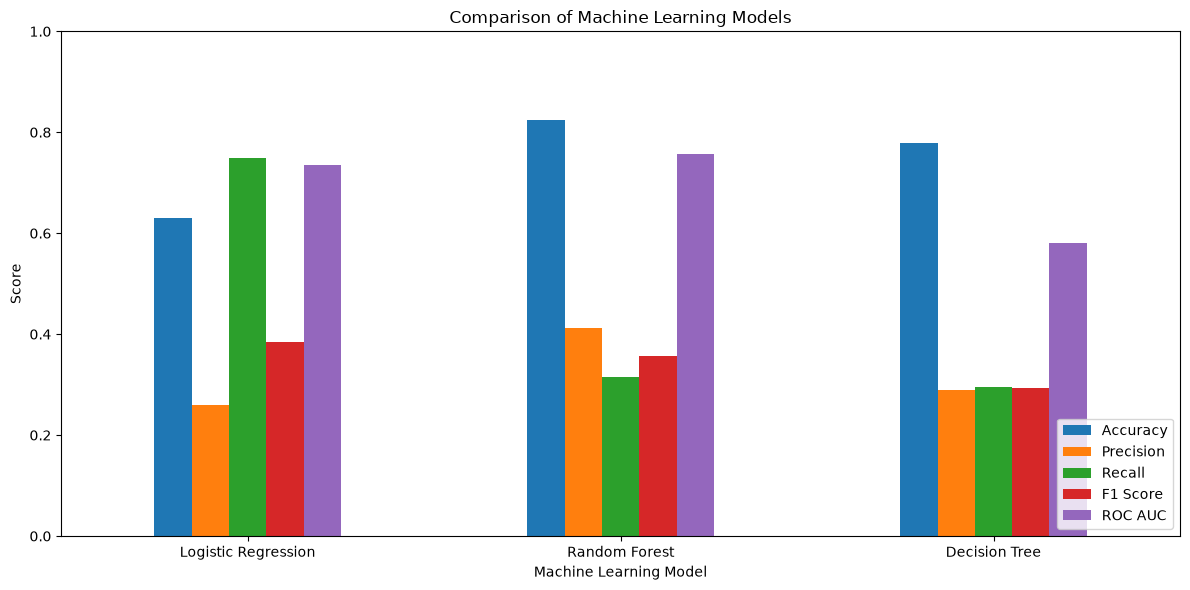

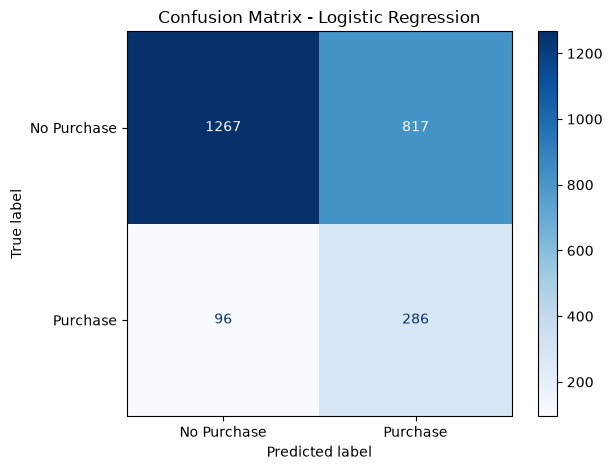

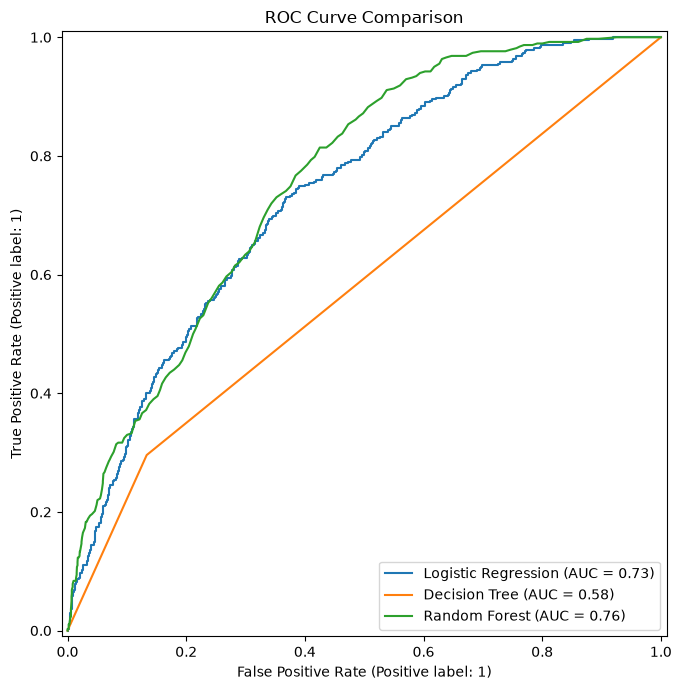


========== FINAL PROJECT SUMMARY ==========
Total records: 12330
Training records: 9864
Testing records: 2466

Best model: Logistic Regression
Best F1 Score: 0.3852

All models trained successfully!
Comparison table saved.
Best model saved.
Evaluation graphs saved.


In [1]:

# ============================================================
# E-COMMERCE CUSTOMER PURCHASE PREDICTION
# MODEL TRAINING AND COMPARISON
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import time

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Libraries imported successfully!")


# 2. LOAD DATASET

df = pd.read_csv(
    "../data/raw/online_shoppers_intention.csv"
)

# Exclude Revenue (target) and PageValues (leakage risk)
X = df.drop(columns=["Revenue", "PageValues"])
y = df["Revenue"].astype(int)

print("Dataset loaded.")
print("Features:", X.shape)
print("Target:", y.shape)


# 3. IDENTIFY FEATURE TYPES

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

numerical_features = [
    column for column in X.columns
    if column not in categorical_features
]


# 4. TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


# 5. RECREATE PREPROCESSING PIPELINE

# We fit preprocessing only on training data.
# This prevents information leakage from the test set.

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline as SklearnPipeline

numerical_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])


# 6. DEFINE MACHINE LEARNING MODELS

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}


# 7. TRAIN MODELS AND EVALUATE PERFORMANCE

results = []
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    # Combine preprocessing and model into one pipeline
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    start_time = time.time()

    # Train model
    pipeline.fit(X_train, y_train)

    training_time = time.time() - start_time

    # Predictions
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": roc_auc,
        "Training Time (seconds)": training_time
    })

    trained_models[name] = pipeline

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Purchase", "Purchase"],
        zero_division=0
    ))


# 8. CREATE MODEL COMPARISON TABLE

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print("\n========== MODEL COMPARISON ==========")
display(results_df.round(4))


# 9. SAVE MODEL COMPARISON RESULTS

os.makedirs("../reports/model_results", exist_ok=True)
os.makedirs("../models", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)

results_df.to_csv(
    "../reports/model_results/model_comparison.csv",
    index=False
)

print("Model comparison saved!")


# 10. SELECT BEST MODEL USING F1 SCORE

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\nBest model based on F1 Score:", best_model_name)


# 11. SAVE BEST MODEL

joblib.dump(
    best_model,
    "../models/best_model.joblib"
)

print("Best model saved successfully!")


# 12. PLOT MODEL COMPARISON

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

comparison_plot = results_df.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    "../reports/figures/model_comparison.png",
    dpi=300
)

plt.show()


# 13. CONFUSION MATRIX FOR BEST MODEL

best_predictions = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()

plt.savefig(
    "../reports/figures/best_model_confusion_matrix.png",
    dpi=300
)

plt.show()


# 14. ROC CURVES FOR ALL MODELS

plt.figure(figsize=(9, 7))

ax = plt.gca()

for name, pipeline in trained_models.items():

    RocCurveDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

plt.title("ROC Curve Comparison")
plt.tight_layout()

plt.savefig(
    "../reports/figures/roc_curve_comparison.png",
    dpi=300
)

plt.show()


# 15. FINAL SUMMARY

print("\n========== FINAL PROJECT SUMMARY ==========")

print("Total records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nBest model:", best_model_name)

print(
    "Best F1 Score:",
    round(results_df.iloc[0]["F1 Score"], 4)
)

print("\nAll models trained successfully!")
print("Comparison table saved.")
print("Best model saved.")
print("Evaluation graphs saved.")


In [2]:
display(
    results_df[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "ROC AUC"
        ]
    ].round(4)
)


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.6298,0.2593,0.7487,0.3852,0.7348
2,Random Forest,0.8244,0.4124,0.3141,0.3566,0.7572
1,Decision Tree,0.7782,0.2890,0.2958,0.2924,0.5812


In [3]:
import os

print("Best model:", best_model_name)

print("\nSaved model:")
print(os.path.exists("../models/best_model.joblib"))

print("\nSaved comparison:")
print(os.path.exists("../reports/model_results/model_comparison.csv"))

print("\nSaved figures:")
for filename in [
    "model_comparison.png",
    "best_model_confusion_matrix.png",
    "roc_curve_comparison.png"
]:
    print(filename, os.path.exists("../reports/figures/" + filename))

Best model: Logistic Regression

Saved model:
True

Saved comparison:
True

Saved figures:
model_comparison.png True
best_model_confusion_matrix.png True
roc_curve_comparison.png True


In [4]:

# ============================================================
# HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import joblib

# 1. CREATE CROSS-VALIDATION STRATEGY
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# 2. CREATE MODEL PIPELINES
tuning_models = {
    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# 3. DEFINE PARAMETER SEARCH SPACES
parameter_spaces = {
    "Decision Tree": {
        "classifier__max_depth": [5, 10, 15, 20, None],
        "classifier__min_samples_split": [2, 5, 10, 20],
        "classifier__min_samples_leaf": [1, 2, 4, 8],
        "classifier__criterion": ["gini", "entropy"]
    },

    "Random Forest": {
        "classifier__max_depth": [10, 20, 30, None],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4],
        "classifier__max_features": ["sqrt", 0.8]
    }
}

# 4. RUN RANDOMIZED SEARCH
tuned_models = {}

for name in tuning_models:

    print("\nTuning:", name)

    search = RandomizedSearchCV(
        estimator=tuning_models[name],
        param_distributions=parameter_spaces[name],
        n_iter=8,
        scoring="f1",
        cv=cv_strategy,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    # Search uses training data only
    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_

    print("\nBest cross-validation F1:", round(search.best_score_, 4))
    print("Best parameters:")
    print(search.best_params_)


# 5. COMPARE BASELINE AND TUNED MODELS
models_to_evaluate = {
    "Logistic Regression (Baseline)": trained_models["Logistic Regression"],
    "Decision Tree (Tuned)": tuned_models["Decision Tree"],
    "Random Forest (Tuned)": tuned_models["Random Forest"]
}

tuning_results = []

for name, model in models_to_evaluate.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    tuning_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df = tuning_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print("\n========== TUNED MODEL COMPARISON ==========")
display(tuning_results_df.round(4))


# 6. SAVE RESULTS
tuning_results_df.to_csv(
    "../reports/model_results/tuned_model_comparison.csv",
    index=False
)

# 7. SELECT AND SAVE BEST MODEL
best_tuned_name = tuning_results_df.iloc[0]["Model"]
best_tuned_model = models_to_evaluate[best_tuned_name]

joblib.dump(
    best_tuned_model,
    "../models/best_model.joblib"
)

print("\nBest model after tuning:", best_tuned_name)
print("Updated best model saved successfully!")


# 8. SHOW FINAL CLASSIFICATION REPORT
final_predictions = best_tuned_model.predict(X_test)

print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))



Tuning: Decision Tree
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best cross-validation F1: 0.3835
Best parameters:
{'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 8, 'classifier__max_depth': 10, 'classifier__criterion': 'gini'}

Tuning: Random Forest
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best cross-validation F1: 0.4203
Best parameters:
{'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None}

========== TUNED MODEL COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Random Forest (Tuned),0.7238,0.2999,0.5864,0.3968,0.7629
0,Logistic Regression (Baseline),0.6298,0.2593,0.7487,0.3852,0.7348
1,Decision Tree (Tuned),0.6050,0.2319,0.6702,0.3445,0.6791



Best model after tuning: Random Forest (Tuned)
Updated best model saved successfully!

Final Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.91      0.75      0.82      2084
    Purchase       0.30      0.59      0.40       382

    accuracy                           0.72      2466
   macro avg       0.60      0.67      0.61      2466
weighted avg       0.81      0.72      0.76      2466



In [5]:
print("Tuned model comparison:")
display(
    tuning_results_df.round(4)
)

print("\nBest model:")
print(best_tuned_name)

print("\nBest model test F1-score:")
print(round(tuning_results_df.iloc[0]["F1 Score"], 4))

Tuned model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Random Forest (Tuned),0.7238,0.2999,0.5864,0.3968,0.7629
0,Logistic Regression (Baseline),0.6298,0.2593,0.7487,0.3852,0.7348
1,Decision Tree (Tuned),0.6050,0.2319,0.6702,0.3445,0.6791



Best model:
Random Forest (Tuned)

Best model test F1-score:
0.3968


TOP 20 IMPORTANT FEATURES


,Feature,Importance
7,num__ExitRates,0.1839
5,num__ProductRelated_Duration,0.1324
4,num__ProductRelated,0.0941
6,num__BounceRates,0.0929
1,num__Administrative_Duration,0.0734
0,num__Administrative,0.0627
16,cat__Month_Nov,0.0351
3,num__Informational_Duration,0.0277
50,cat__TrafficType_2,0.0197
71,cat__VisitorType_Returning_Visitor,0.0167


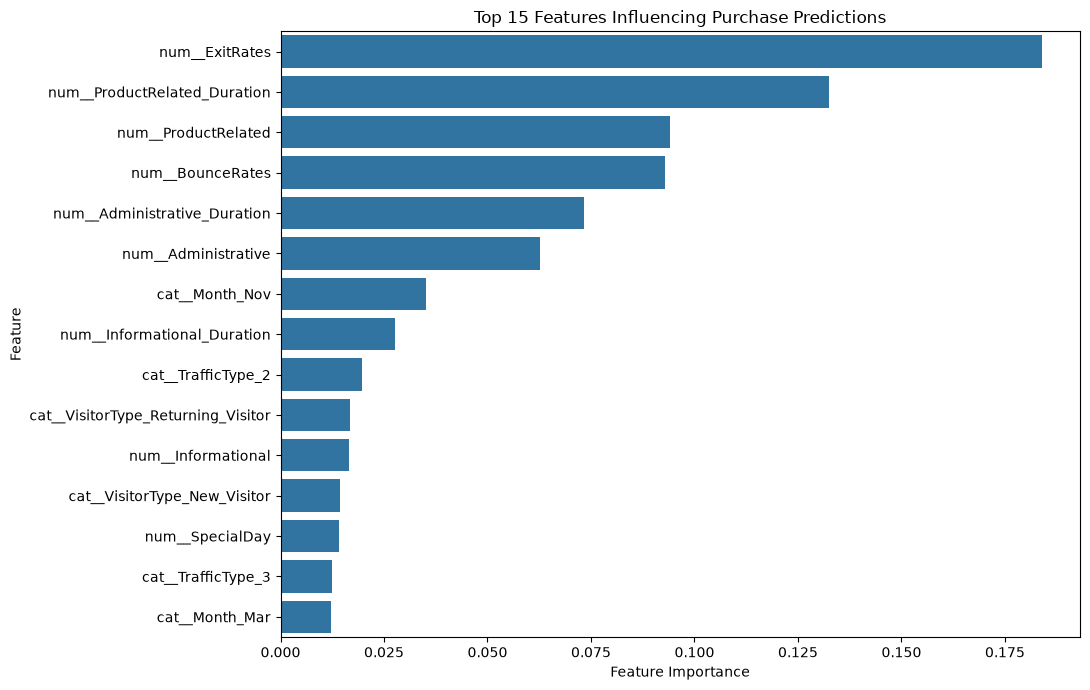

Feature importance analysis completed!
Results and graph saved successfully!


In [6]:

# ============================================================
# FEATURE IMPORTANCE ANALYSIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Get the fitted preprocessing component
fitted_preprocessor = best_tuned_model.named_steps["preprocessor"]

# 2. Get names of all transformed features
feature_names = fitted_preprocessor.get_feature_names_out()

# 3. Extract feature importance from Random Forest
classifier = best_tuned_model.named_steps["classifier"]

importance_values = classifier.feature_importances_

# 4. Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# 5. Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 20 IMPORTANT FEATURES")
display(feature_importance.head(20).round(4))

# 6. Plot top 15 features
top_features = feature_importance.head(15)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Purchase Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

# 7. Save graph
os.makedirs("../reports/figures", exist_ok=True)

plt.savefig(
    "../reports/figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 8. Save feature importance results
feature_importance.to_csv(
    "../reports/model_results/feature_importance.csv",
    index=False
)

print("Feature importance analysis completed!")
print("Results and graph saved successfully!")


Subtraining records: 7891
Validation records: 1973

Model trained for threshold selection!

THRESHOLD COMPARISON


,Threshold,Precision,Recall,F1 Score
0,0.10,0.1817,0.9934,0.3071
1,0.15,0.1891,0.9770,0.3169
2,0.20,0.1986,0.9541,0.3288
3,0.25,0.2096,0.9410,0.3429
4,0.30,0.2271,0.9180,0.3641
5,0.35,0.2408,0.8623,0.3765
6,0.40,0.2593,0.8000,0.3917
7,0.45,0.2746,0.7148,0.3967
8,0.50,0.2972,0.5934,0.3961
9,0.55,0.3347,0.5180,0.4067



Best validation threshold: 0.55


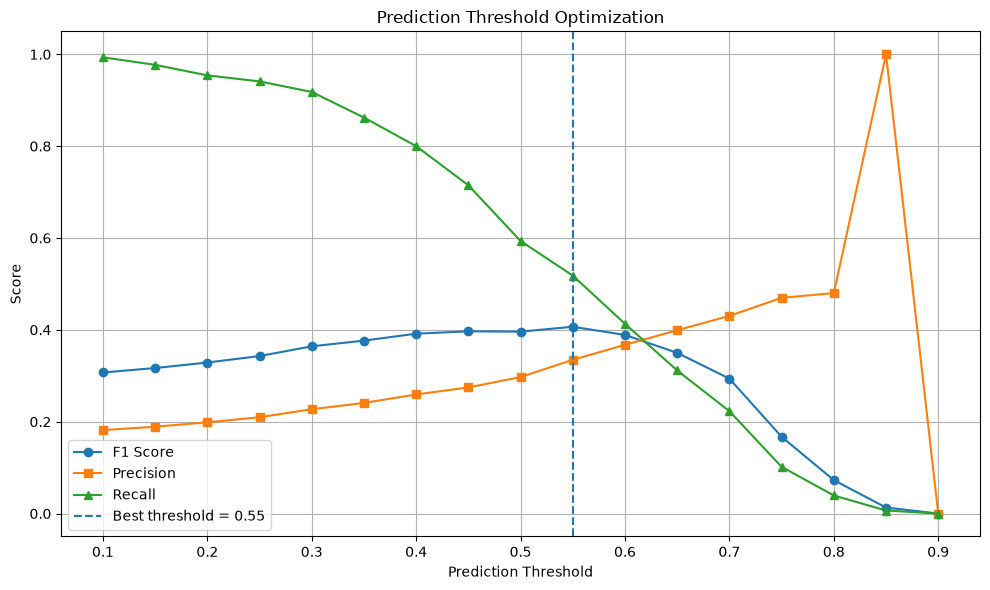


FINAL TEST RESULTS AT OPTIMIZED THRESHOLD
Accuracy: 0.7648
Precision: 0.3238
Recall: 0.4764
F1 Score: 0.3856
ROC AUC: 0.7584

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Purchase       0.89      0.82      0.85      2084
    Purchase       0.32      0.48      0.39       382

    accuracy                           0.76      2466
   macro avg       0.61      0.65      0.62      2466
weighted avg       0.81      0.76      0.78      2466

Confusion Matrix:
[[1704  380]
 [ 200  182]]

Threshold analysis completed!
Model and optimized threshold saved!


In [7]:

# ============================================================
# PREDICTION THRESHOLD OPTIMIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import os

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. DIVIDE TRAINING DATA INTO TRAINING AND VALIDATION SETS

X_subtrain, X_validation, y_subtrain, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Subtraining records:", len(X_subtrain))
print("Validation records:", len(X_validation))


# 2. CREATE A FRESH COPY OF OUR BEST MODEL

threshold_model = clone(best_tuned_model)

# Train only on subtraining data
threshold_model.fit(X_subtrain, y_subtrain)

print("\nModel trained for threshold selection!")


# 3. GET PURCHASE PROBABILITIES ON VALIDATION DATA

validation_probabilities = threshold_model.predict_proba(
    X_validation
)[:, 1]


# 4. TEST DIFFERENT THRESHOLDS

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_validation, predictions, zero_division=0
        )
    })


# 5. DISPLAY RESULTS

threshold_df = pd.DataFrame(threshold_results)

print("\nTHRESHOLD COMPARISON")
display(threshold_df.round(4))


# 6. FIND THE BEST THRESHOLD BASED ON VALIDATION F1

best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

print("\nBest validation threshold:", best_threshold)


# 7. PLOT F1 SCORE AGAINST THRESHOLD

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="s",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="^",
    label="Recall"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best threshold = {best_threshold}"
)

plt.xlabel("Prediction Threshold")
plt.ylabel("Score")
plt.title("Prediction Threshold Optimization")
plt.legend()
plt.grid(True)
plt.tight_layout()

os.makedirs("../reports/figures", exist_ok=True)

plt.savefig(
    "../reports/figures/threshold_optimization.png",
    dpi=300
)

plt.show()


# 8. EVALUATE ON THE UNTOUCHED TEST SET

test_probabilities = threshold_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("\nFINAL TEST RESULTS AT OPTIMIZED THRESHOLD")

print("Accuracy:", round(
    accuracy_score(y_test, test_predictions), 4
))

print("Precision:", round(
    precision_score(y_test, test_predictions, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, test_predictions, zero_division=0), 4
))

print("F1 Score:", round(
    f1_score(y_test, test_predictions, zero_division=0), 4
))

print("ROC AUC:", round(
    roc_auc_score(y_test, test_probabilities), 4
))


# 9. CLASSIFICATION REPORT

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    test_predictions,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))


# 10. CONFUSION MATRIX

cm = confusion_matrix(y_test, test_predictions)

print("Confusion Matrix:")
print(cm)


# 11. SAVE THRESHOLD RESULTS

threshold_df.to_csv(
    "../reports/model_results/threshold_comparison.csv",
    index=False
)

# Save model and threshold together
joblib.dump(
    {
        "model": threshold_model,
        "threshold": float(best_threshold)
    },
    "../models/purchase_prediction_model.joblib"
)

print("\nThreshold analysis completed!")
print("Model and optimized threshold saved!")


In [8]:

# ============================================================
# FINAL MODEL TRAINING AND TEST EVALUATION
# ============================================================

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import joblib
import os

# 1. RETRAIN MODEL ON THE FULL TRAINING DATA

final_model = clone(best_tuned_model)

final_model.fit(X_train, y_train)

print("Final model trained on full training data!")


# 2. PREDICT PURCHASE PROBABILITIES ON TEST DATA

final_probabilities = final_model.predict_proba(X_test)[:, 1]


# 3. APPLY THE SELECTED VALIDATION THRESHOLD

final_predictions = (
    final_probabilities >= best_threshold
).astype(int)


# 4. CALCULATE FINAL TEST METRICS

print("\n========== FINAL TEST RESULTS ==========")

print("Selected threshold:", best_threshold)

print("Accuracy:",
      round(accuracy_score(y_test, final_predictions), 4))

print("Precision:",
      round(precision_score(y_test, final_predictions, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, final_predictions, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_test, final_predictions, zero_division=0), 4))

print("ROC AUC:",
      round(roc_auc_score(y_test, final_probabilities), 4))


# 5. CLASSIFICATION REPORT

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    final_predictions,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))


# 6. CONFUSION MATRIX

print("\nCONFUSION MATRIX")

print(confusion_matrix(y_test, final_predictions))


# 7. SAVE FINAL MODEL AND THRESHOLD

os.makedirs("../models", exist_ok=True)

joblib.dump(
    {
        "model": final_model,
        "threshold": float(best_threshold)
    },
    "../models/purchase_prediction_model.joblib"
)

print("\nFinal model and threshold saved successfully!")



Final model trained on full training data!

========== FINAL TEST RESULTS ==========
Selected threshold: 0.55
Accuracy: 0.7725
Precision: 0.3382
Recall: 0.4895
F1 Score: 0.4
ROC AUC: 0.7629

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Purchase       0.90      0.82      0.86      2084
    Purchase       0.34      0.49      0.40       382

    accuracy                           0.77      2466
   macro avg       0.62      0.66      0.63      2466
weighted avg       0.81      0.77      0.79      2466


CONFUSION MATRIX
[[1718  366]
 [ 195  187]]

Final model and threshold saved successfully!
